# Comparing feature importance measures

This native Julia companion preserves the original experiment, observations, sample sizes, parameters and decision rules. Fixed public NumPy draws, fold assignments, permutations and bootstrap primitives replay the original seeded experiments. The supplied native binary Gini forest preserves the chapter’s unbalanced bootstrap classifier, Float32 split inputs, distinct-observation leaf limits and weighted leaf probabilities; feature-importance calculations use the native RiskLabAI caller-estimator interfaces. Rolling sums retain the public compensated arithmetic, and principal-component signs follow the public divide-and-conquer eigensolver convention before classifier fitting. The original distinction between published methods and the released simplified calculations is preserved. Figures use the requested dark theme, and native outputs are saved under `outputs/julia`.

Gini impurity measures class mixing, a split receives credit for reducing that mixing, and MDI adds the credit assigned to one feature:

$$
i(t)=1-\sum_{c=1}^{C}p_{c\mid t}^{,2},
\qquad
\Delta i(s,t)=i(t)-p_Li(t_L)-p_Ri(t_R),
\qquad
\operatorname{MDI}_j=\frac{1}{B}\sum_{b=1}^{B}\sum_{t\in T_b:v(t)=j}p(t)\Delta i(t).
$$

Here, $t$ is a tree node; $C$ is the number of classes; $p_{c\mid t}$ is the share of class $c$ in node $t.$ $s$ is a candidate split; $t_L,t_R$ are its child nodes; $p_L,p_R$ are their shares of the parent observations. $B$ is the number of trees; $T_b$ is tree $b$; $v(t)=j$ means node $t$ splits on feature $j$; $p(t)$ is the node sample share.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("14_feature_importance");
using CSV, TOML, Printf
include(joinpath("..","support","BookForest.jl"))
using RiskLabAI.Features: feature_importance_mdi,feature_importance_mda,feature_importance_sfi,clustered_feature_importance_mdi,clustered_feature_importance_mda,orthogonal_features,calculate_weighted_tau,mdi_plus_importance,conditional_predictive_impact
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
public_lines = readlines(data_path)
header_row = findfirst(startswith(",Agric"),public_lines)
end_row = findnext(line->isempty(strip(line)),public_lines,header_row+1)
raw = CSV.read(IOBuffer(join(public_lines[header_row:end_row-1],"\n")),DataFrame)
rename!(raw,names(raw)[1]=>"Date")
all_dates = Date.(string.(raw.Date),dateformat"yyyymmdd")
all_returns = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all((all_returns.!=-99.99).&(all_returns.!=-999.0);dims=2))
industry_dates = all_dates[valid]
industry_names = names(raw)[2:end]
industry_returns = all_returns[valid,:]./100
violet = "#C084FC"


selected_features = ["Food","Beer","Hshld","Oil","Coal","Mines","Hardw","Softw","Chips","Banks","Insur","Fin"]
cluster_names = ["Consumer","Resources","Technology","Finance"]
clusters = [name=>collect(3index-2:3index) for (index,name) in enumerate(cluster_names)]
columns = [findfirst(==(name),industry_names) for name in selected_features]

"""Match the public rolling sum's separate add/remove Kahan compensations."""
function rolling_sum(values,window)
    all(isfinite,values) || throw(ArgumentError("complete finite observations are required"))
    result = fill(NaN,length(values))
    total,add_compensation,remove_compensation = 0.,0.,0.
    previous,consecutive = first(values),0
    for index in eachindex(values)
        if index>window
            correction = -values[index-window]-remove_compensation
            updated = total+correction
            remove_compensation = (updated-total)-correction
            total = updated
        end
        value = values[index]
        correction = value-add_compensation
        updated = total+correction
        add_compensation = (updated-total)-correction
        total = updated
        consecutive = value==previous ? consecutive+1 : 1
        previous = value
        if index>=window
            result[index] = consecutive>=window ? previous*window : total
        end
    end
    return result
end

public_x = hcat([rolling_sum(industry_returns[:,column],5)[5:end-1] for column in columns]...)
public_y = Int.(vec(mean(industry_returns[6:end,:];dims=2)).>0)
public_dates = industry_dates[6:end]
input_root = joinpath("..","data","chapter14_random_inputs")
manifest_path = joinpath(input_root,"inputs.toml")
input_manifest = TOML.parsefile(manifest_path)["files"]
input_cache = Dict{String,DataFrame}()
audit_context = Ref("")
audit_fits,audit_nodes,audit_importances,audit_predictions = NamedTuple[],NamedTuple[],NamedTuple[],NamedTuple[]
audit_models = IdDict{Any,Int}()
audit_calls = Dict{Int,Int}()

function primitive(name)
    filename = name*".csv"
    return get!(input_cache,filename) do
        path = joinpath(input_root,filename)
        CSV.read(path,DataFrame)
    end
end

forest(seed;trees=120,depth=5,leaf=10,features=1) = (;seed,trees,depth=depth===nothing ? typemax(Int32) : depth,leaf,features=features===nothing ? 0 : features)

function begin_audit(name)
    audit_context[] = name
    foreach(empty!,(audit_fits,audit_nodes,audit_importances,audit_predictions,audit_models,audit_calls))
    return nothing
end

function fit_native(estimator,x,y,weights)
    specification = estimator isa BookForest.ClassificationForest ? estimator.specification : estimator
    @assert weights===nothing || all(==(1),weights)
    plan = Matrix{Int}(primitive("forest_$(specification.seed)_$(length(y))_$(Int(weights!==nothing))"))
    fitted = BookForest.fit_forest(specification,x,y,plan[3:end,:],vec(plan[2,:]))
    fit = length(audit_fits)+1
    audit_models[fitted] = fit
    audit_calls[fit] = 0
    push!(audit_fits,(fit=fit,seed=specification.seed,observations=length(y),features=size(x,2),trees=specification.trees,depth=specification.depth,leaf=specification.leaf,max_features=specification.features,weighted=weights!==nothing))
    for (tree_index,tree) in enumerate(fitted.trees)
        for (index,node) in enumerate(tree.nodes)
            push!(audit_nodes,(fit=fit,tree=tree_index,node=index,feature=node.feature,threshold=node.threshold,left=node.left,right=node.right,count=node.count,mass=node.mass,positive=node.positive_mass,impurity=node.impurity))
        end
        for (feature,value) in enumerate(tree.importance)
            push!(audit_importances,(fit=fit,tree=tree_index,feature=feature,importance=value))
        end
    end
    return fitted
end

function predict_native(model,x)
    probabilities = BookForest.predict_proba(model,x)
    fit = audit_models[model]
    audit_calls[fit] += 1
    append!(audit_predictions,[(fit=fit,call=audit_calls[fit],row=index,p0=probabilities[index,1],p1=probabilities[index,2]) for index in axes(x,1)])
    return probabilities
end

function finish_audit()
    prefix = audit_context[]
    for (suffix,records) in [("fits",audit_fits),("nodes",audit_nodes),("tree_importance",audit_importances),("predictions",audit_predictions)]
        isempty(records) || save_data(DataFrame(records),paths,prefix*"_"*suffix)
    end
    return nothing
end

function saved_importance(name,result,labels)
    save_data(DataFrame(Feature=labels,Mean=result.mean,StandardDeviation=result.std),paths,name*"_importance")
    finish_audit()
    return result
end

function fixed_folds(seed)
    membership = primitive("folds_$(seed)").fold
    return [(findall(!=(fold),membership),findall(==(fold),membership)) for fold in 1:maximum(membership)]
end

function mdi(name,x,y,estimator;groups=nothing,labels=string.(axes(x,2)))
    begin_audit(name)
    options = (;fit_estimator=fit_native,tree_importances=BookForest.tree_importances)
    result = groups===nothing ? feature_importance_mdi(estimator,x,y;options...) : clustered_feature_importance_mdi(estimator,x,y,groups;options...)
    return saved_importance(name,result,labels)
end

function mda(name,x,y,estimator,seed;groups=nothing,labels=string.(axes(x,2)))
    begin_audit(name)
    folds = fixed_folds(seed)
    values = Matrix{Int}(primitive("permutations_$(seed)"))
    permutations = [[values[values[:,1].==fold,column] for column in 2:size(values,2)] for fold in eachindex(folds)]
    options = (;fit_estimator=fit_native,predict_proba=predict_native,estimator_classes=_->[0,1],folds,permutations,n_splits=length(folds),random_state=seed)
    result = groups===nothing ? feature_importance_mda(estimator,x,y;options...) : clustered_feature_importance_mda(estimator,x,y,groups;options...)
    return saved_importance(name,result,labels)
end

function sfi(name,x,y,estimator;labels=string.(axes(x,2)))
    begin_audit(name)
    result = feature_importance_sfi(estimator,x,y;fit_estimator=fit_native,predict=(model,values)->Int.(predict_native(model,values)[:,2].>.5),scoring=:accuracy,n_splits=5)
    return saved_importance(name,result,labels)
end

function table(frame,name,caption)
    save_table(frame,paths,name;caption,label="tab:chapter12-"*replace(name,"_"=>"-"))
    return nothing
end

function standard_panels(frame,label,title,name)
    order = sortperm(frame.MDI)
    panels = []
    for (column,color) in zip(["MDI","MDA log-loss decrease","SFI accuracy"],[palette.cyan,palette.amber,palette.green])
        lower,upper = min(0,minimum(frame[!,column])),max(0,maximum(frame[!,column]))
        span = max(upper-lower,eps(Float64))
        panel = bar(1:nrow(frame),frame[order,column];orientation=:h,yticks=(1:nrow(frame),frame[order,label]),color,linealpha=0,alpha=.85,legend=false,title=column,xlabel="Score",ylims=(.4,nrow(frame)+.6),xlims=(lower-.04span,upper+.12span),left_margin=5Plots.mm)
        vline!(panel,[0.];color=palette.text,linewidth=.8,label=false)
        push!(panels,panel)
    end
    save_figure(plot(panels...;layout=(1,3),size=(1500,650),plot_title=title,plot_titlefontsize=13),paths,name)
    return nothing
end

public_frame = hcat(DataFrame(Date=public_dates,Target=public_y),DataFrame(public_x,selected_features))
save_data(public_frame,paths,"public_predictors");


## Public Industry Prediction Task

In [2]:
data_provenance = DataFrame("Field"=>["Archive","Provider","Provider database vintage","Return type","Analysis start","Analysis end","Daily observations","Industry portfolios"],"Value"=>["49_Industry_Portfolios_daily_CSV.zip","Kenneth R. French Data Library","202608 CRSP database","Daily value-weighted return",string(first(industry_dates)),string(last(industry_dates)),"1,760","49"])
table(data_provenance,"data_provenance","Fixed public observations used in Chapter 12.")
public_task_summary = DataFrame("Quantity"=>["Usable dates","Predictors","Lookback days","Forecast step","Positive target share","First target date","Last target date"],"Value"=>string.([size(public_x,1),size(public_x,2),5,1,mean(public_y),string(first(public_dates)),string(last(public_dates))]))
table(public_task_summary,"public_task_summary","Public descriptive prediction task for feature-importance comparison.")


9×2 DataFrame
 Row │ Field                      Value
     │ String                     String
─────┼──────────────────────────────────────────────────────────────
   1 │ Archive                    49_Industry_Portfolios_daily_CSV…
   2 │ Provider                   Kenneth R. French Data Library
   3 │ Provider database vintage  202608 CRSP database
   4 │ Return type                Daily value-weighted return
   5 │ Analysis start             2019-01-02
   6 │ Analysis end               2025-12-31
   7 │ Daily observations         1,760
   8 │ Industry portfolios        49

Row,Quantity,Value
,String,String
1,Usable dates,1755
2,Predictors,12
3,Lookback days,5
4,Forecast step,1
5,Positive target share,0.5316239316239316
6,First target date,2019-01-09
7,Last target date,2025-12-31


## Mean Decrease in Impurity

In [3]:
public_mdi = mdi("public_mdi",public_x,public_y,forest(1201);labels=selected_features);


## Mean Decrease in Predictive Score

Permutation importance is the average loss in held-out predictive score after one feature is randomly reordered:

$$
\operatorname{MDA}_j
=\frac{1}{K}\sum_{k=1}^{K}\left(S_k-S_{k,j}^{\pi}\right).
$$

Here, $K$ is the number of data folds; $k$ labels a fold; $S_k$ is its original score. $S_{k,j}^{\pi}$ is the score after feature $j$ is permuted in the held-out rows; $\pi$ denotes the random reordering. $\operatorname{MDA}_j$ is the mean score decrease, so a larger positive value gives more evidence that the fitted predictor used feature $j.$

In [4]:
public_mda = mda("public_mda",public_x,public_y,forest(1202),1203;labels=selected_features);


## Single-Feature Importance

Single-feature importance reports how well a model predicts when it is allowed to use only one feature:

$$
\operatorname{SFI}_j
=\frac{1}{K}\sum_{k=1}^{K}S\!\left(\widehat f_j^{(-k)},D_k\right).
$$

Here, $K$ is the number of folds; $D_k$ is held-out fold $k$; $\widehat f_j^{(-k)}$ is fitted on all other folds using only feature $j.$ $S(\widehat f,D)$ is the chosen predictive score on data $D$; $\operatorname{SFI}_j$ is the average score for feature $j$ alone.

Row,Industry,MDI,MDA log-loss decrease,SFI accuracy
,String,Float64,Float64,Float64
1,Food,0.098615,0.00247681,0.521368
2,Beer,0.0734722,0.000389209,0.508262
3,Hshld,0.0835013,0.000517356,0.507123
4,Oil,0.0800586,-0.000327173,0.530484
5,Coal,0.0962669,0.000722032,0.533333
6,Mines,0.0878483,-0.000534246,0.533333
7,Hardw,0.0734581,0.000128977,0.501994
8,Softw,0.0678495,0.000181218,0.506553
9,Chips,0.0976054,-0.000410171,0.525356


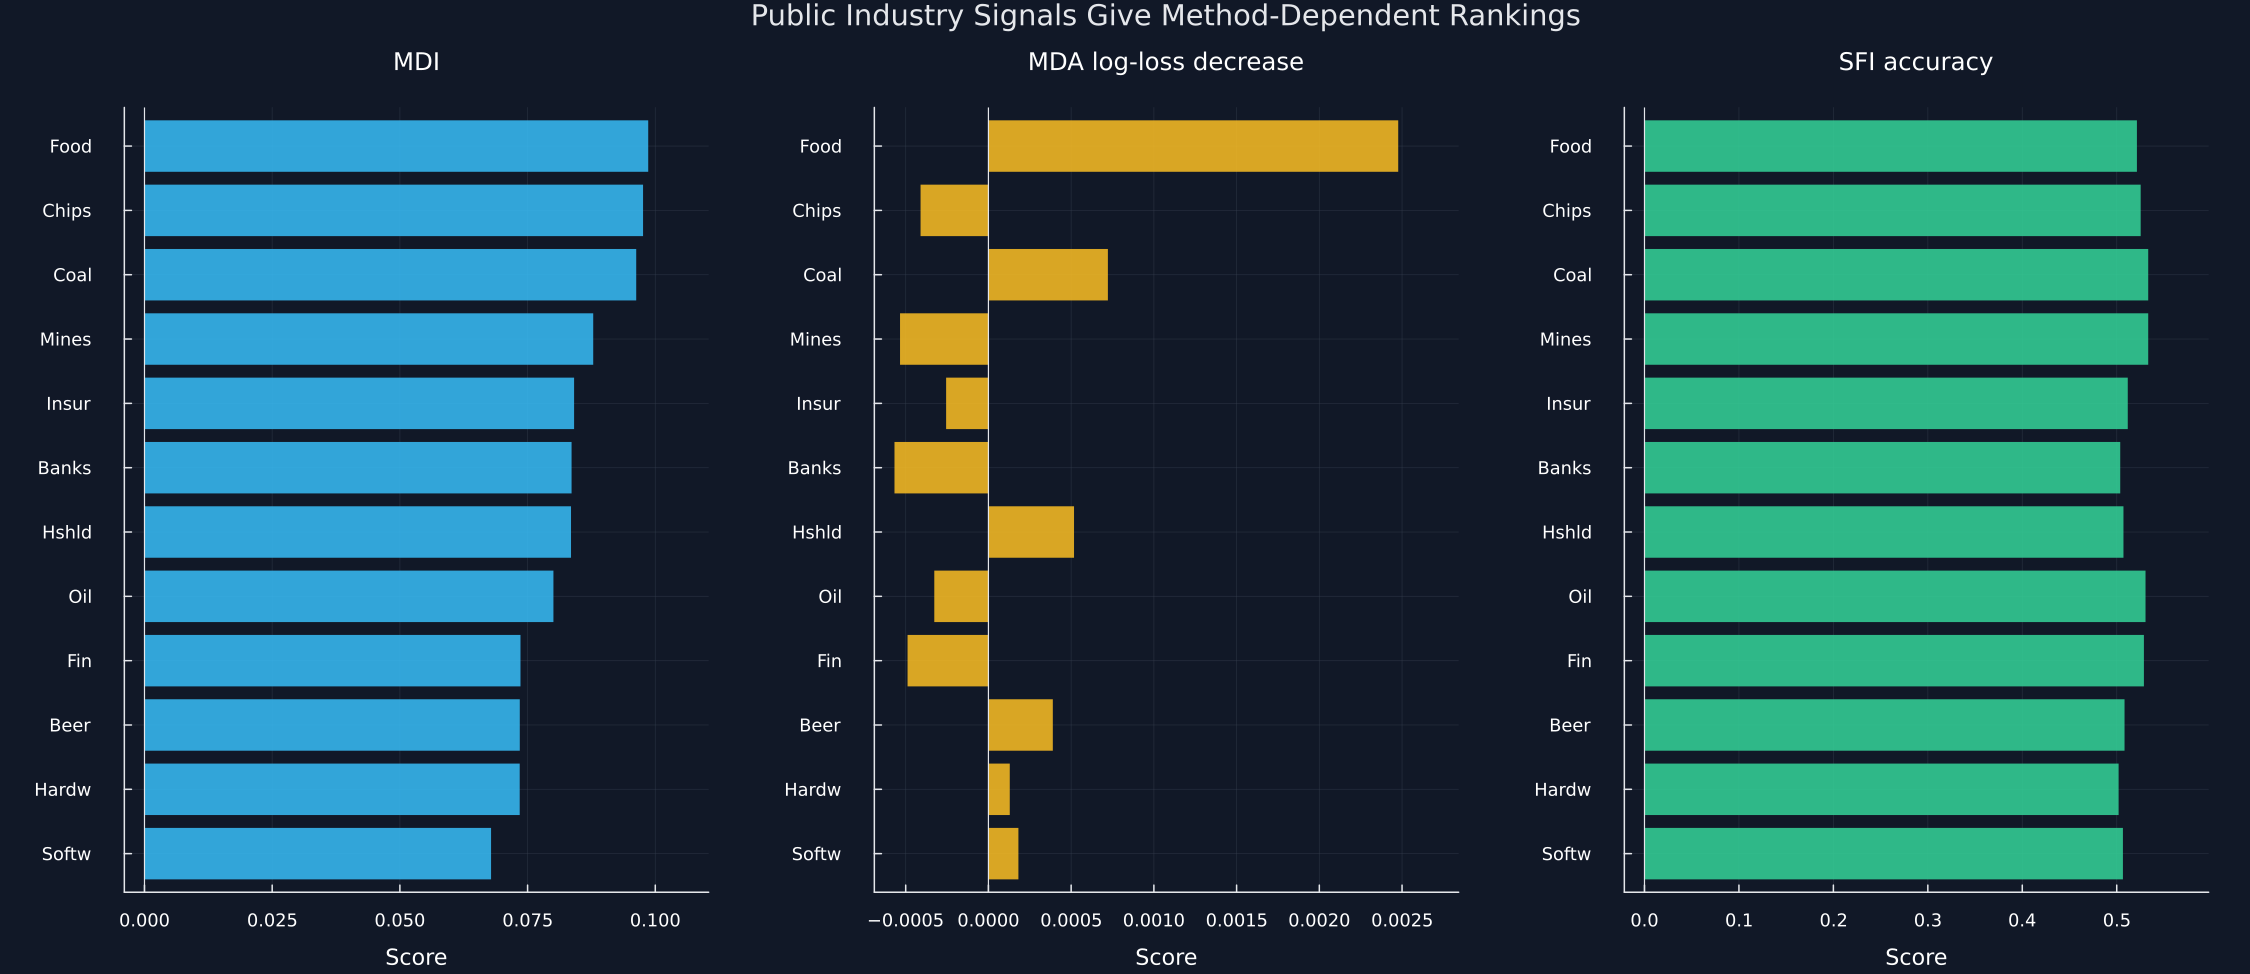

In [5]:
public_sfi = sfi("public_sfi",public_x,public_y,forest(1204);labels=selected_features)
public_standard_importance = DataFrame("Industry"=>selected_features,"MDI"=>public_mdi.mean,"MDA log-loss decrease"=>public_mda.mean,"SFI accuracy"=>public_sfi.mean)
table(public_standard_importance,"public_standard_importance","Three feature-importance summaries on the public descriptive task.")
standard_panels(public_standard_importance,"Industry","Public Industry Signals Give Method-Dependent Rankings","public_standard_importance")


## Recovering relevance despite redundancy

The controlled label depends on two known signals, while two extra variables are noisy copies that can substitute for them:

$$
Y=\mathbf 1\!\left\{1.4Z_1+Z_2+0.8\varepsilon>0\right\},
\qquad
R_1=Z_1+0.08\eta_1,
\qquad
R_2=Z_2+0.08\eta_2.
$$

Here, $Y$ is the binary label; $\mathbf 1\{\cdot\}$ equals one when its condition is true; $Z_1,Z_2$ are independent signals. $R_1,R_2$ are redundant copies; $\varepsilon,\eta_1,\eta_2$ are independent standard-normal shocks; $1.4,1,0.8,0.08$ are fixed signal and noise scales.

Row,Feature,Role,Distinct values
,String,String,Int64
1,Signal one,Direct signal,1200
2,Signal two,Direct signal,1200
3,Copy one,Redundant signal,1200
4,Copy two,Redundant signal,1200
5,Continuous noise,Noise,1200
6,Five-level noise,Noise,5


Row,Feature,MDI,MDA log-loss decrease,SFI accuracy,Role
,String,Float64,Float64,Float64,String
1,Signal one,0.321299,0.142847,0.7475,Direct signal
2,Signal two,0.147391,0.0602524,0.628333,Direct signal
3,Copy one,0.325812,0.115014,0.765,Redundant signal
4,Copy two,0.152387,0.0678056,0.63,Redundant signal
5,Continuous noise,0.0395191,0.00190353,0.499167,Noise
6,Five-level noise,0.0135924,0.000610019,0.493333,Noise


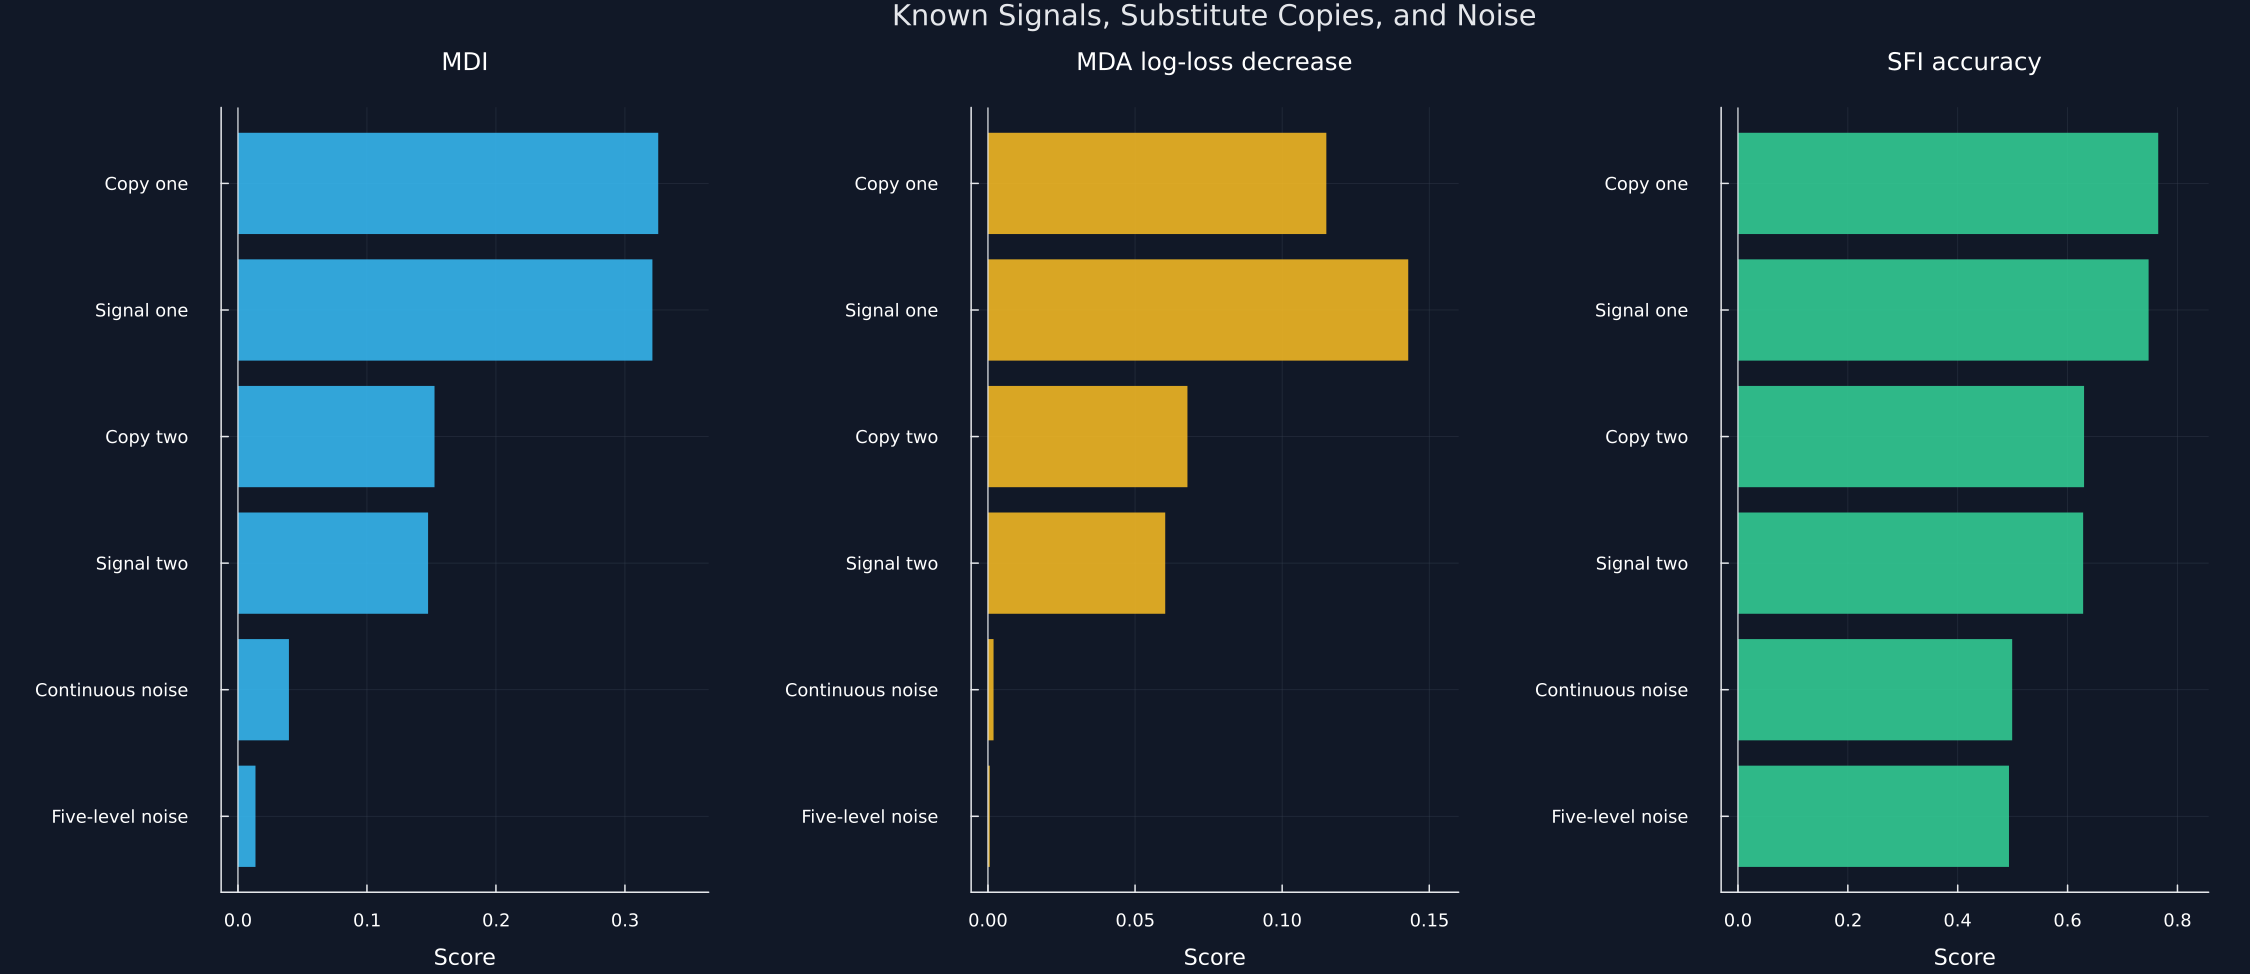

In [6]:
draws = primitive("controlled_draws")
controlled_names = ["Signal one","Signal two","Copy one","Copy two","Continuous noise","Five-level noise"]
controlled_x = hcat(draws.signal_one,draws.signal_two,draws.signal_one.+.08draws.copy_one_noise,draws.signal_two.+.08draws.copy_two_noise,draws.continuous_noise,draws.five_level_noise)
controlled_y = Int.((1.4draws.signal_one.+draws.signal_two.+.8draws.target_noise).>0)
controlled_mdi = mdi("controlled_mdi",controlled_x,controlled_y,forest(1221;trees=160,depth=6,leaf=8);labels=controlled_names)
controlled_mda = mda("controlled_mda",controlled_x,controlled_y,forest(1222;trees=160,depth=6,leaf=8),1223;labels=controlled_names)
controlled_sfi = sfi("controlled_sfi",controlled_x,controlled_y,forest(1224;trees=160,depth=6,leaf=8);labels=controlled_names)
roles = ["Direct signal","Direct signal","Redundant signal","Redundant signal","Noise","Noise"]
controlled_design = DataFrame("Feature"=>controlled_names,"Role"=>roles,"Distinct values"=>[length(unique(controlled_x[:,column])) for column in axes(controlled_x,2)])
controlled_standard_importance = DataFrame("Feature"=>controlled_names,"MDI"=>controlled_mdi.mean,"MDA log-loss decrease"=>controlled_mda.mean,"SFI accuracy"=>controlled_sfi.mean,"Role"=>roles)
table(controlled_design,"controlled_standard_design","Known-truth feature roles for the standard-method comparison.")
table(controlled_standard_importance,"controlled_standard_importance","Standard importance measures on the known-truth design.")
save_data(hcat(DataFrame(Target=controlled_y),DataFrame(controlled_x,controlled_names)),paths,"controlled_predictors")
standard_panels(controlled_standard_importance,"Feature","Known Signals, Substitute Copies, and Noise","controlled_standard_importance")


## Tests

In [7]:
@assert size(industry_returns)==(1760,49)
@assert size(public_x)==(1755,12)
@assert length(public_dates)==length(public_y)
@assert issorted(public_dates) && allunique(public_dates)
@assert all(isfinite,public_x)
@assert all(in((0,1)),public_y)
@assert .45<mean(public_y)<.60
@assert length(public_mdi.mean)==length(public_mdi.std)==12
@assert sum(public_mdi.mean)≈1
@assert all(>=(0),public_mdi.mean)
@assert length(public_mda.mean)==length(public_mda.std)==12
@assert length(public_sfi.mean)==length(public_sfi.std)==12
@assert all(value->0<=value<=1,public_sfi.mean)
@assert size(public_standard_importance)==(12,4)
@assert size(controlled_x)==(1200,6)
@assert all(in((0,1)),controlled_y)
@assert size(controlled_standard_importance)==(6,5)
@assert sum(controlled_mdi.mean[1:4])>.9
@assert minimum(controlled_mda.mean[1:4])>.04
@assert maximum(controlled_mda.mean[5:6])<.02
@assert minimum(controlled_sfi.mean[1:4])>maximum(controlled_sfi.mean[5:6])+.10
@assert isfile(joinpath(paths.figures,"public_standard_importance.pdf"))
@assert isfile(joinpath(paths.figures,"controlled_standard_importance.pdf"))
@assert isfile(joinpath(paths.tables,"public_standard_importance.tex"))
@assert isfile(joinpath(paths.tables,"controlled_standard_importance.tex"))
